# 07 — Ranker training data and features

| Copy | Candidates + features from | Labels from |
|---|---|---|
| `ranker_train` | data before T1 (2022-07-01) | validation window, T1 → T2 |
| `ranker_test` | data before T2 (2023-01-01) = train + validation | test window, after T2 |

Both copies come from the same function, `shoprank.ranking.dataset.build_snapshot`, which refits every retrieval source on the history before its cutoff. Models fit in Phase 6 on train only (sentiment classifier, segment scaler + K-Means) are reused with `.predict()`, never refit on later data.

Leakage test: `tests/test_leakage.py` rebuilds the T1 copy with everything after T1 scrambled and checks every feature is unchanged.

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import SelectKBest, chi2

sys.path.insert(0, "../src")
from shoprank.nlp.sentiment import review_text
from shoprank.ranking.dataset import ALL_FEATURES, build_snapshot
from shoprank.ranking.preprocess import CATEGORICAL, DROPPED, FEATURES, NUMERIC, make_preprocessor

T1, T2 = pd.Timestamp("2022-07-01"), pd.Timestamp("2023-01-01")
PROC, FIG, MODELS = Path("../data/processed"), Path("../reports/figures"), Path("../models")

train = pd.read_parquet(PROC / "train.parquet").merge(pd.read_parquet(PROC / "train_sentiment.parquet"),
                                                      on=["user_id", "parent_asin"], validate="1:1")
val = pd.read_parquet(PROC / "val.parquet")
test = pd.read_parquet(PROC / "test.parquet")
items = pd.read_parquet(PROC / "items.parquet")
embeddings = np.load(PROC / "item_embeddings.npy")
segments = joblib.load(MODELS / "segments.joblib")
sentiment = joblib.load(MODELS / "sentiment_lr.joblib")

## Review sentiment for every interaction

Train reviews keep their out-of-fold probability from 06a. Validation and test reviews are scored by the train-fit model, so no probability ever comes from a model that saw later data.

In [2]:
for df in (val, test):
    df["p_positive"] = sentiment["model"].predict_proba(sentiment["vectorizer"].transform(review_text(df)))[:, 1]
interactions = pd.concat([train, val, test], ignore_index=True)
print(f"{len(interactions):,} interactions, {interactions['timestamp'].min().date()} -> {interactions['timestamp'].max().date()}")

184,567 interactions, 2018-01-01 -> 2023-09-02


## Steps 1–4 — Candidates, labels, features for both copies

In [3]:
copies, recall = {}, {}
for name, cutoff, label_end in [("train", T1, T2), ("test", T2, None)]:
    t = time.time()
    copies[name], recall[name] = build_snapshot(interactions, items, embeddings, segments, cutoff, label_end)
    print(f"{name}: built in {time.time() - t:.0f}s")

def summary(df):
    has_pos = df.groupby("user_id")["label"].max()
    return {"rows": len(df), "users": df["user_id"].nunique(), "positives": int(df["label"].sum()),
            "positive rate": df["label"].mean(), "users with a positive": has_pos.mean()}

before = pd.DataFrame({name: summary(df) | {"candidate recall": recall[name]["recall"]} for name, df in copies.items()})
before

train: built in 8s


test: built in 7s


,train,test
rows,696065.000000,571098.000000
users,4549.000000,3719.000000
positives,1417.000000,1247.000000
positive rate,0.002036,0.002184
users with a positive,0.250824,0.259209
candidate recall,0.147670,0.141664


## Step 3 — Drop users with no positive candidate from the training copy only

They teach the ranker nothing. The test copy keeps them so test scores stay honest (those users count as misses).

In [4]:
ranker_train = copies["train"][copies["train"].groupby("user_id")["label"].transform("max") == 1].reset_index(drop=True)
ranker_test = copies["test"]
after = pd.DataFrame({"train": summary(ranker_train), "test": summary(ranker_test)})
after

,train,test
rows,174135.000000,571098.000000
users,1141.000000,3719.000000
positives,1417.000000,1247.000000
positive rate,0.008137,0.002184
users with a positive,1.000000,0.259209


## Step 6 — Feature selection (on the training copy only)

### Correlation heatmap

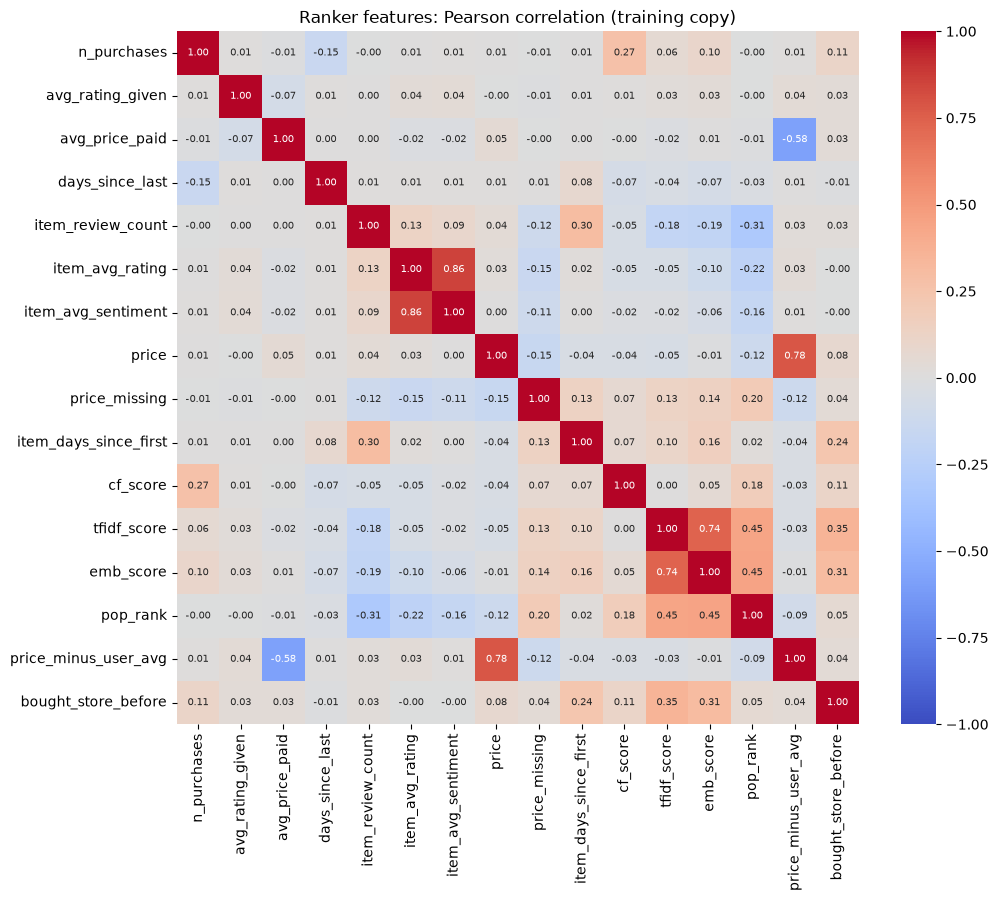

pairs with |r| > 0.9: none
strongest pairs: [('item_avg_rating', 'item_avg_sentiment', np.float64(0.857)), ('price', 'price_minus_user_avg', np.float64(0.784)), ('tfidf_score', 'emb_score', np.float64(0.735)), ('avg_price_paid', 'price_minus_user_avg', np.float64(-0.579))]


In [5]:
numeric_all = [f for f in ALL_FEATURES if f not in CATEGORICAL]
corr = ranker_train[numeric_all].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Ranker features: Pearson correlation (training copy)")
plt.savefig(FIG / "ranker_feature_corr.png", dpi=120, bbox_inches="tight")
plt.show()

pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(numeric_all) for b in numeric_all[i + 1:]]
pairs = sorted(pairs, key=lambda p: -abs(p[2]))
print("pairs with |r| > 0.9:", [p for p in pairs if abs(p[2]) > 0.9] or "none")
print("strongest pairs:", pairs[:4])

No pair passes 0.9. Pairwise correlation misses one exact dependency: `price_minus_user_avg = price - avg_price_paid`, so those three columns are perfectly collinear together.

In [6]:
gap = (ranker_train["price"] - ranker_train["avg_price_paid"] - ranker_train["price_minus_user_avg"]).abs().max()
rank = np.linalg.matrix_rank(ranker_train[["price", "avg_price_paid", "price_minus_user_avg"]].to_numpy())
print(f"max |price - avg_price_paid - price_minus_user_avg| = {gap:.2e}, matrix rank of the 3 columns = {rank}")

max |price - avg_price_paid - price_minus_user_avg| = 0.00e+00, matrix rank of the 3 columns = 2


### Pearson correlation with the label (quick screen)

With 0.8% positives every |r| is small; this screen only flags features with no linear signal at all. User-level features are constant within a user's candidate list, so on their own they cannot reorder it — they can only help a tree model through interactions with product features.

In [7]:
label_corr = ranker_train[numeric_all].corrwith(ranker_train["label"]).sort_values(key=abs, ascending=False)
label_corr.round(4).to_frame("r with label")

,r with label
bought_store_before,0.0450
item_review_count,0.0360
tfidf_score,0.0242
cf_score,0.0235
emb_score,0.0229
item_days_since_first,-0.0213
price_missing,-0.0192
pop_rank,-0.0167
price,0.0137
price_minus_user_avg,0.0113


### Chi-square on the one-hot categoricals

In [8]:
onehot = make_preprocessor(numeric=[], categorical=CATEGORICAL).fit(ranker_train)
X_cat = onehot.transform(ranker_train)
selector = SelectKBest(chi2, k="all").fit(X_cat, ranker_train["label"])
chi = pd.DataFrame({"column": onehot.get_feature_names_out(), "chi2": selector.scores_, "p": selector.pvalues_})
chi["group"] = chi["column"].str.split("__").str[0]
print(chi.groupby("group").agg(columns=("p", "size"), significant=("p", lambda p: (p < 0.05).sum())))
chi.sort_values("chi2", ascending=False).head(10).round(4)

         columns  significant
group                        
segment        6            2
store         51           26


,column,chi2,p,group
35,store__store_PlayStation,144.4753,0.0000,store
56,store__store_infrequent_sklearn,35.2748,0.0000,store
45,store__store_Turtle Beach,26.8882,0.0000,store
53,store__store_eXtremeRate,23.5562,0.0000,store
32,store__store_Nintendo,18.6374,0.0000,store
34,store__store_PWNAGE,16.5271,0.0000,store
29,store__store_Meta Quest,13.1224,0.0003,store
48,store__store_WolfLawS,12.5651,0.0004,store
24,store__store_KIWI design,9.0541,0.0026,store
52,store__store_amFilm,8.9675,0.0027,store


In [9]:
chi[chi["group"] == "segment"].round(4)

,column,chi2,p,group
0,segment__segment_id_0,4.1242,0.0423,segment
1,segment__segment_id_1,1.0771,0.2994,segment
2,segment__segment_id_2,0.0528,0.8183,segment
3,segment__segment_id_3,1.5051,0.2199,segment
4,segment__segment_id_4,4.3095,0.0379,segment
5,segment__segment_id_5,2.1518,0.1424,segment


### Final feature list

Kept in `shoprank.ranking.preprocess` (`NUMERIC`, `CATEGORICAL`, `DROPPED`) so Phase 8 and the API use the same list. Weak-screen features stay for now; Phase 8 rechecks with model importance and SHAP.

In [10]:
assert set(FEATURES) | set(DROPPED) == set(ALL_FEATURES)
print(f"{len(FEATURES)} features: {len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical")
for f, why in DROPPED.items():
    print(f"dropped {f}: {why}")

17 features: 15 numeric + 2 categorical
dropped avg_price_paid: exactly price - price_minus_user_avg (perfect collinearity) and the weakest label correlation


## Step 5 — Encode and scale inside a Pipeline-ready ColumnTransformer

Fit on the training copy only; the test copy is only transformed.

In [11]:
pre = make_preprocessor().fit(ranker_train[FEATURES])
Xtr, Xte = pre.transform(ranker_train[FEATURES]), pre.transform(ranker_test[FEATURES])
print(f"train {Xtr.shape}, test {Xte.shape}; numeric means after scaling (train) ~0: {np.abs(Xtr[:, :len(NUMERIC)].mean(0)).max():.1e}")
unseen = ~ranker_test["store"].isin(ranker_train["store"])
print(f"test rows whose store never appears in train: {unseen.mean():.1%} (handled as infrequent / ignored)")

train (174135, 72), test (571098, 72); numeric means after scaling (train) ~0: 2.9e-13


test rows whose store never appears in train: 1.8% (handled as infrequent / ignored)


## Step 7 — Save

In [12]:
ranker_train.to_parquet(PROC / "ranker_train.parquet", index=False)
ranker_test.to_parquet(PROC / "ranker_test.parquet", index=False)
for f in ["ranker_train.parquet", "ranker_test.parquet"]:
    df = pd.read_parquet(PROC / f)
    print(f"{f:22} {len(df):>8,} rows  {df['user_id'].nunique():>5,} users  positive rate {df['label'].mean():.2%}")

ranker_train.parquet    174,135 rows  1,141 users  positive rate 0.81%


ranker_test.parquet     571,098 rows  3,719 users  positive rate 0.22%
